# ML Challenge 2026: Business Entity Resolution EDA

This notebook profiles the three sources (train and test) and the training ground truth, then writes a summary to `eda_summary.md`.

**Memory note:** the raw TSVs total about 2.5 GB. Every file is **streamed in chunks**. Cheap statistics are computed on the *full* files. Expensive string work (similarity, tokens) runs on samples:
- a random background sample of each file (`BG_SAMPLE_RATE`)
- `GT_SAMPLE` Source-1 entities from the ground truth, plus all their true matches

Set `EDA_MAX_ROWS=200000` in the environment for a quick smoke run.

In [1]:
import os, re, csv, gc, time, unicodedata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from rapidfuzz import fuzz
from sklearn.metrics import roc_auc_score
from IPython.display import display, Markdown

DATA = Path("dataset")
MAX_ROWS = int(os.environ.get("EDA_MAX_ROWS", 0)) or None   # None = full files
CHUNK = 500_000
GT_SAMPLE = 30_000          # S1 entities (train GT) used for pair-level analysis
BG_SAMPLE_RATE = 0.02       # random fraction of every file kept in memory
SEED = 42
rng = np.random.default_rng(SEED)

FILES = {
    ("train", "S1"): DATA / "train/train_source1.tsv",
    ("train", "S2"): DATA / "train/train_source2.tsv",
    ("train", "S3"): DATA / "train/train_source3.tsv",
    ("test",  "S1"): DATA / "test/test_source1.tsv",
    ("test",  "S2"): DATA / "test/test_source2.tsv",
    ("test",  "S3"): DATA / "test/test_source3.tsv",
}
GT_PATH = DATA / "train/train_ground_truth.tsv"
READ_KW = dict(sep="\t", dtype=str, keep_default_na=False, quoting=csv.QUOTE_NONE)

# Palette: a fixed categorical order that has been validated for colour-blind separation. Colour follows the entity.
SRC_COL = {"S1": "#2a78d6", "S2": "#eb6834", "S3": "#1baf7a"}
CTRY_COL = {"US": "#4a3aa7", "India": "#eda100", "France": "#e87ba4"}
PAIR_COL = {"true match": "#2a78d6", "hard negative": "#eb6834", "random negative": "#b8b7b0"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e6e5e0", "figure.dpi": 110, "axes.titleweight": "bold"})
t0 = time.time()

## 1. File inventory

In [2]:
inv = []
for (split, src), p in FILES.items():
    inv.append({"split": split, "source": src, "file": p.name, "size_MB": round(p.stat().st_size / 1e6, 1)})
inv.append({"split": "train", "source": "GT", "file": GT_PATH.name, "size_MB": round(GT_PATH.stat().st_size / 1e6, 1)})
inv = pd.DataFrame(inv)
display(pd.read_csv(FILES[("train", "S1")], nrows=5, **READ_KW))
display(pd.read_csv(GT_PATH, nrows=5, **READ_KW))
inv

,entity_id,business_name,business_address,country
0,S1-925783039,Orelee's Barbershop,"1795 Westchester Drive, High Point, NC",US
1,S1-773889195,Prime Money,"17560 Ellis Road, Tahlequah, OK",US
2,S1-377745466,B+ Retail Inc,"1712 Montebello Avenue, Phoenix, AZ",US
3,S1-133037285,Christ Chapel,"2100 Cameron Drive, Unit APARTMENT G, Dundalk, MD",US
4,S1-755362802,Prabhav Business Center,"797, Lake Town Block A, Kolkata, Howrah, West ...",India


,source1_entity_id,matched_entity_ids
0,S1-965667,"S2-681193310,S2-743505751,S3-775321672,S3-1129..."
1,S1-55344266,"S2-249013014,S2-197070651,S3-478195123,S3-3843..."
2,S1-343815751,"S2-790675320,S2-479876582,S3-878454467"
3,S1-656753428,"S2-153058913,S2-24659151,S3-679606215"
4,S1-102811957,"S2-478959098,S2-553508714,S2-625774905,S3-7280..."


,split,source,file,size_MB
0,train,S1,train_source1.tsv,210.1
1,train,S2,train_source2.tsv,489.3
2,train,S3,train_source3.tsv,503.7
3,test,S1,test_source1.tsv,175.0
4,test,S2,test_source2.tsv,509.5
5,test,S3,test_source3.tsv,506.0
6,train,GT,train_ground_truth.tsv,127.0


## 2. Load the ground truth

Entity IDs have the form `S{k}-{integer}`, so each one is encoded as an int64 (`k * 1e10 + n`). This lets us check for membership across millions of IDs without holding Python string sets in memory.

In [3]:
def id_to_int(s: pd.Series) -> np.ndarray:
    s = s.astype(str)
    return s.str.slice(1, 2).astype("int64").to_numpy() * 10**10 + s.str.slice(3).astype("int64").to_numpy()

gt = pd.read_csv(GT_PATH, nrows=MAX_ROWS, **READ_KW)
gt["n_match"] = np.where(gt.matched_entity_ids == "", 0, gt.matched_entity_ids.str.count(",") + 1)
gt["n_s2"] = gt.matched_entity_ids.str.count("S2-")
gt["n_s3"] = gt.matched_entity_ids.str.count("S3-")

# Explode all matched IDs as ints (cheap), and remember which S1 each one belongs to
exp = gt.loc[gt.n_match > 0, ["source1_entity_id", "matched_entity_ids"]]
exp = exp.assign(m=exp.matched_entity_ids.str.split(",")).explode("m")
pairs_int = pd.DataFrame({"s1": id_to_int(exp.source1_entity_id), "m": id_to_int(exp.m)})
del exp; gc.collect()

matched_sorted = np.sort(pairs_int.m.to_numpy())
dup_targets = int((pairs_int.m.value_counts() > 1).sum())
print(f"GT rows: {len(gt):,} | total true pairs: {len(pairs_int):,}")
print(f"S2/S3 ids linked to more than one S1 entity: {dup_targets:,}  (0 means each S2/S3 record belongs to at most one S1)")

# Pick the GT sample used for pair analysis
gt_sample = gt.sample(min(GT_SAMPLE, len(gt)), random_state=SEED)
sample_s1_int = id_to_int(gt_sample.source1_entity_id)
sample_pairs = pairs_int[pairs_int.s1.isin(sample_s1_int)]
NEEDED = {"S1": set(sample_s1_int.tolist()),
          "S2": set(sample_pairs.m[sample_pairs.m // 10**10 == 2].tolist()),
          "S3": set(sample_pairs.m[sample_pairs.m // 10**10 == 3].tolist())}
print({k: len(v) for k, v in NEEDED.items()})

GT rows: 2,206,821 | total true pairs: 7,638,365
S2/S3 ids linked to more than one S1 entity: 0  (0 means each S2/S3 record belongs to at most one S1)
{'S1': 30000, 'S2': 50340, 'S3': 53528}


## 3. Streaming profile of every file

A single pass over each file computes:
- country mix, empty fields, and field lengths
- scripts used (Latin, accented Latin, and the Indic scripts)
- postal-code patterns, literal `null` tokens, all-caps addresses, URLs in names, and junk prefixes
- exact duplicates of (name, address) within the file
- **distractor rate**: the share of train S2/S3 records that appear in *no* ground-truth list

It also keeps a random background sample of each file, plus the train records needed for the GT sample.

In [4]:
SCRIPTS = {
    "Devanagari": "ऀ-ॿ", "Bengali": "ঀ-৿", "Gurmukhi": "਀-੿",
    "Gujarati": "઀-૿", "Odia": "଀-୿", "Tamil": "஀-௿",
    "Telugu": "ఀ-౿", "Kannada": "ಀ-೿", "Malayalam": "ഀ-ൿ",
}
INDIC_RE = "[" + "".join(SCRIPTS.values()) + "]"
LMAX = 300

def chunk_features(df: pd.DataFrame) -> pd.DataFrame:
    n, a = df.business_name, df.business_address
    f = pd.DataFrame(index=df.index)
    f["rows"] = 1
    f["empty_name"] = n.str.strip() == ""
    f["empty_addr"] = a.str.strip() == ""
    f["name_len"] = n.str.len()
    f["addr_len"] = a.str.len()
    f["name_tokens"] = n.str.count(r"\S+")
    f["addr_commas"] = a.str.count(",")
    f["nonascii_name"] = n.str.contains(r"[^\x00-\x7F]", regex=True)
    f["nonascii_addr"] = a.str.contains(r"[^\x00-\x7F]", regex=True)
    f["indic_name"] = n.str.contains(INDIC_RE, regex=True)
    f["indic_addr"] = a.str.contains(INDIC_RE, regex=True)
    f["accented_latin_name"] = n.str.contains("[À-ɏ]", regex=True)
    f["null_token_addr"] = a.str.contains(r"\bnull\b", case=False, regex=True)
    f["pin6_addr"] = a.str.contains(r"(?<!\d)\d{3}\s?\d{3}(?!\d)", regex=True)
    f["zip5_addr"] = a.str.contains(r"(?<!\d)\d{5}(?!\d)", regex=True)
    f["upper_addr"] = (a == a.str.upper()) & a.str.contains("[A-Za-z]", regex=True)
    f["url_in_name"] = n.str.contains(r"www\.|\.com\b|\.in\b|\.fr\b", case=False, regex=True)
    f["junk_prefix_name"] = n.str.contains(r"^\W", regex=True)
    f["country"] = df.country
    return f

def scan(split, src, path):
    agg, name_hist, addr_hist, hashes, keep, id_c = None, np.zeros(LMAX + 1, int), np.zeros(LMAX + 1, int), [], [], []
    script_counts = Counter()
    distractor = Counter() if (split == "train" and src != "S1") else None
    need = NEEDED.get(src, set()) if split == "train" else set()
    need_arr = np.fromiter(need, dtype=np.int64)
    for df in pd.read_csv(path, chunksize=CHUNK, nrows=MAX_ROWS, **READ_KW):
        f = chunk_features(df)
        g = f.groupby("country").sum(numeric_only=True)
        agg = g if agg is None else agg.add(g, fill_value=0)
        name_hist += np.bincount(np.minimum(f.name_len.to_numpy(), LMAX), minlength=LMAX + 1)
        addr_hist += np.bincount(np.minimum(f.addr_len.to_numpy(), LMAX), minlength=LMAX + 1)
        hashes.append(pd.util.hash_pandas_object(df[["business_name", "business_address"]], index=False).to_numpy())
        for s, rgx in SCRIPTS.items():
            script_counts[s] += int(df.business_name.str.contains(f"[{rgx}]", regex=True).sum())
        ids = id_to_int(df.entity_id)
        if src == "S1":
            id_c.append(pd.DataFrame({"id": ids, "country": df.country.to_numpy()}))
        if distractor is not None:
            is_m = np.isin(ids, matched_sorted, assume_unique=False)
            for c, v in pd.Series(is_m).groupby(df.country.to_numpy()).agg(["sum", "count"]).iterrows():
                distractor[(c, "matched")] += int(v["sum"]); distractor[(c, "total")] += int(v["count"])
        bgmask = rng.random(len(df)) < BG_SAMPLE_RATE
        mask = bgmask | np.isin(ids, need_arr) if need else bgmask
        keep.append(df[mask].assign(split=split, source=src, id_int=ids[mask], is_bg=bgmask[mask]))
    h = np.concatenate(hashes)
    dup_rate = 1 - len(np.unique(h)) / len(h)
    return dict(agg=agg, name_hist=name_hist, addr_hist=addr_hist, dup_rate=dup_rate,
                scripts=script_counts, distractor=distractor, keep=pd.concat(keep),
                id_country=pd.concat(id_c) if id_c else None)

R = {}
for key, path in FILES.items():
    t = time.time()
    R[key] = scan(*key, path)
    print(f"{key}: {int(R[key]['agg'].rows.sum()):,} rows in {time.time() - t:.0f}s")
    gc.collect()

('train', 'S1'): 2,206,821 rows in 23s


('train', 'S2'): 5,034,616 rows in 107s


('train', 'S3'): 5,285,603 rows in 108s


('test', 'S1'): 1,732,544 rows in 19s


('test', 'S2'): 4,887,273 rows in 55s


('test', 'S3'): 5,082,316 rows in 55s


## 4. Volume and country mix

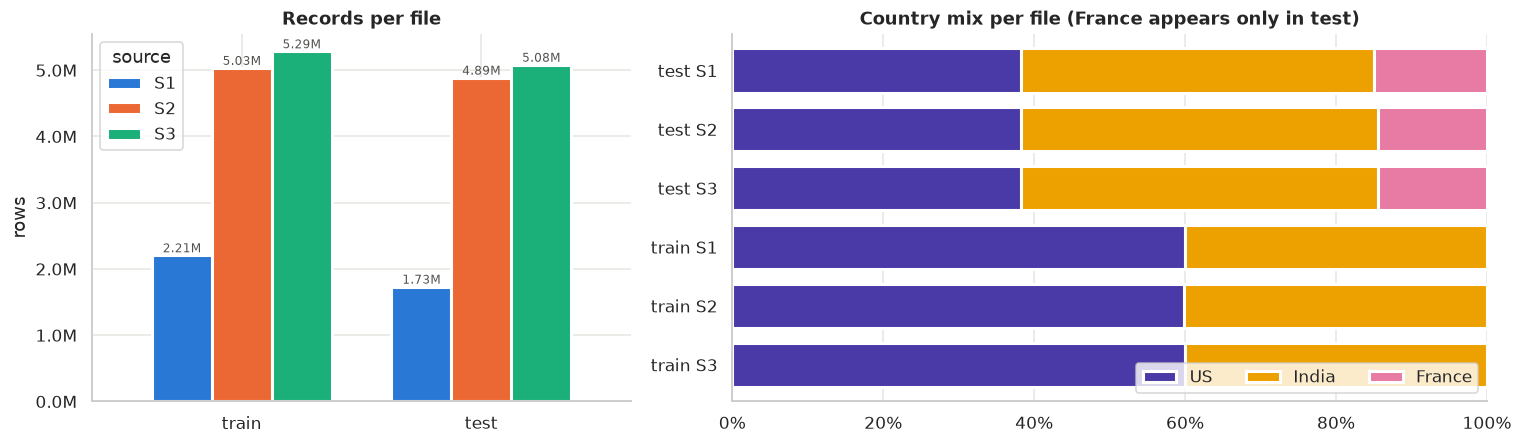

country       France    India       US
split source                          
test  S1      259452   809986   663106
      S2      703378  2312565  1871330
      S3      731615  2405000  1945701
train S1           0   883188  1323633
      S2           0  2017799  3016817
      S3           0  2115547  3170056

In [5]:
rows = pd.DataFrame([{"split": s, "source": src, "rows": int(r["agg"].rows.sum())} for (s, src), r in R.items()])
ctry = pd.concat([r["agg"].rows.rename("rows").reset_index().assign(split=s, source=src) for (s, src), r in R.items()])
ctry["share"] = ctry.rows / ctry.groupby(["split", "source"]).rows.transform("sum")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
p = rows.pivot(index="split", columns="source", values="rows").loc[["train", "test"]]
p.plot.bar(ax=ax, color=[SRC_COL[c] for c in p.columns], width=0.75, edgecolor="white", linewidth=2, rot=0)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
ax.set_title("Records per file"); ax.set_xlabel(""); ax.set_ylabel("rows")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v/1e6:.2f}M" for v in c.datavalues], fontsize=8, color="#52514e")

ax = axes[1]
cp = ctry.pivot_table(index=["split", "source"], columns="country", values="share", fill_value=0)
cp = cp.reindex(columns=[c for c in ["US", "India", "France"] if c in cp.columns] + [c for c in cp.columns if c not in CTRY_COL])
cp.index = [f"{a} {b}" for a, b in cp.index]
cp.plot.barh(stacked=True, ax=ax, color=[CTRY_COL.get(c, "#888") for c in cp.columns], edgecolor="white", linewidth=2, width=0.75)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.invert_yaxis()
ax.set_title("Country mix per file (France appears only in test)"); ax.legend(title="", ncol=3, loc="lower right", frameon=True)
plt.tight_layout(); plt.show()

ctry.pivot_table(index=["split", "source"], columns="country", values="rows", fill_value=0).astype(int)

## 5. Data quality and noise indicators, per file × country

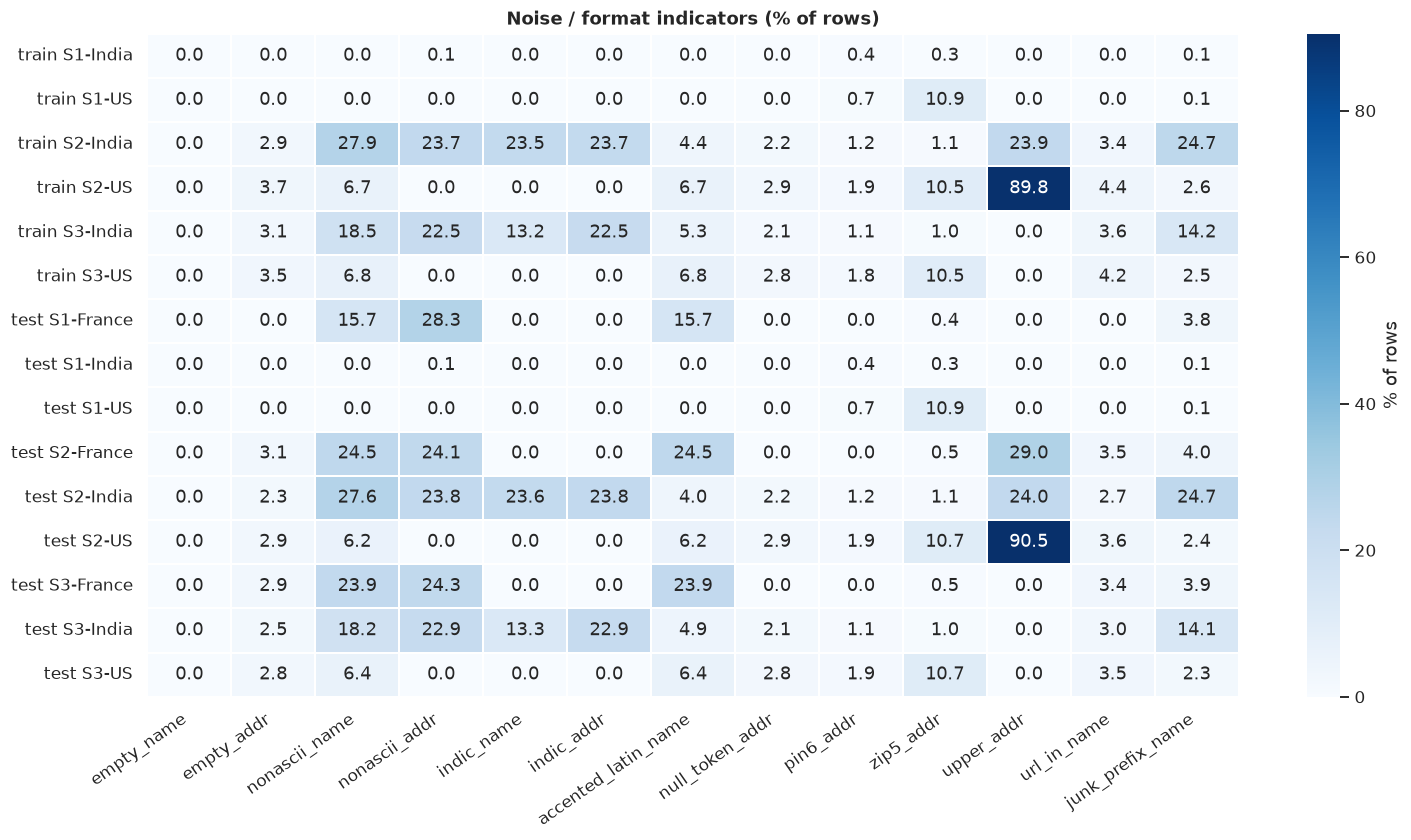

,"exact (name,address) duplicate rate"
train S1,0.00%
train S2,0.51%
train S3,0.36%
test S1,0.00%
test S2,0.46%
test S3,0.32%


rows  avg_name_len  avg_addr_len  avg_addr_commas
file     country                                                      
train S1 India     883188          26.4          77.7              4.7
         US       1323633          22.5          35.0              2.2
train S2 India    2017799          27.4          68.2              3.9
         US       3016817          23.6          31.5              2.0
train S3 India    2115547          27.0          59.1              3.7
         US       3170056          24.0          38.4              2.1
test S1  France    259452          19.4          50.1              2.0
         India     809986          26.4          77.7              4.7
         US        663106          22.5          35.0              2.2
test S2  France    703378          21.1          39.5              1.6
         India    2312565          28.3          68.7              3.9
         US       1871330          24.3          31.8              2.0
test S3  France    731615          21.1          40.0              1.7
         India    2405000          27.9          59.4              3.7
         US       1945701          24.6          38.8              2.1

In [6]:
RATE_COLS = ["empty_name", "empty_addr", "nonascii_name", "nonascii_addr", "indic_name", "indic_addr",
             "accented_latin_name", "null_token_addr", "pin6_addr", "zip5_addr", "upper_addr",
             "url_in_name", "junk_prefix_name"]
q = []
for (s, src), r in R.items():
    a = r["agg"]
    for c in a.index:
        row = {"file": f"{s} {src}", "country": c, "rows": int(a.loc[c, "rows"])}
        row.update({k: a.loc[c, k] / a.loc[c, "rows"] for k in RATE_COLS})
        row["avg_name_len"] = a.loc[c, "name_len"] / a.loc[c, "rows"]
        row["avg_addr_len"] = a.loc[c, "addr_len"] / a.loc[c, "rows"]
        row["avg_addr_commas"] = a.loc[c, "addr_commas"] / a.loc[c, "rows"]
        q.append(row)
quality = pd.DataFrame(q).set_index(["file", "country"])

hm = quality[RATE_COLS] * 100
fig, ax = plt.subplots(figsize=(14, 0.42 * len(hm) + 1.5))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of rows"}, linewidths=1, linecolor="white", ax=ax)
ax.set_title("Noise / format indicators (% of rows)"); ax.set_ylabel(""); ax.set_xlabel("")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

dup = pd.Series({f"{s} {src}": r["dup_rate"] for (s, src), r in R.items()}, name="exact (name,address) duplicate rate")
display(dup.map("{:.2%}".format).to_frame())
quality[["rows", "avg_name_len", "avg_addr_len", "avg_addr_commas"]].round(1)

## 6. Field length distributions (full files)

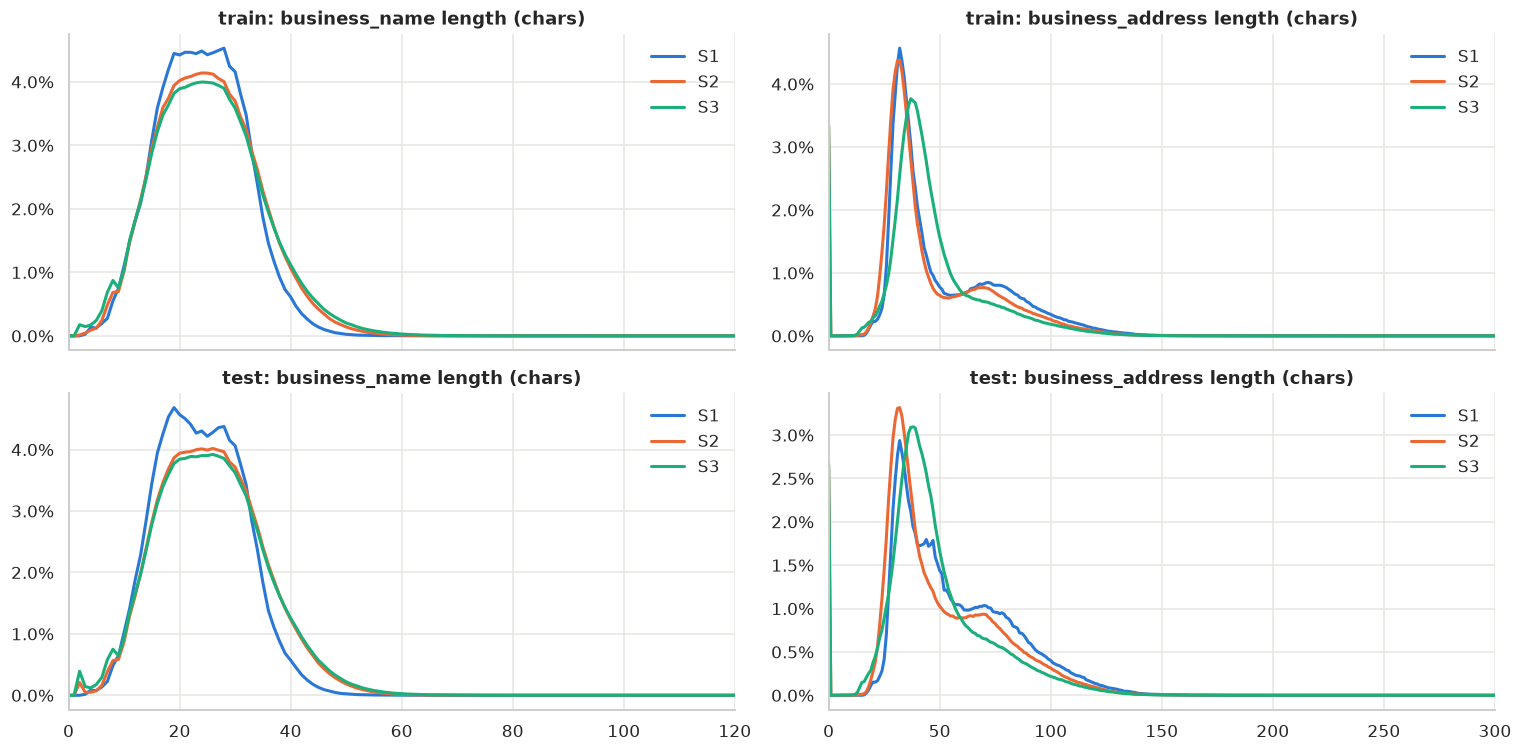

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex="col")
for j, field in enumerate(["name_hist", "addr_hist"]):
    for i, split in enumerate(["train", "test"]):
        ax = axes[i, j]
        for src in ["S1", "S2", "S3"]:
            h = R[(split, src)][field]
            x = np.arange(len(h))
            ax.plot(x, h / h.sum(), lw=2, color=SRC_COL[src], label=src)
        ax.set_xlim(0, 120 if field == "name_hist" else LMAX)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
        ax.set_title(f"{split}: {'business_name' if j == 0 else 'business_address'} length (chars)")
        ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 7. Scripts in `business_name` (transliteration noise)

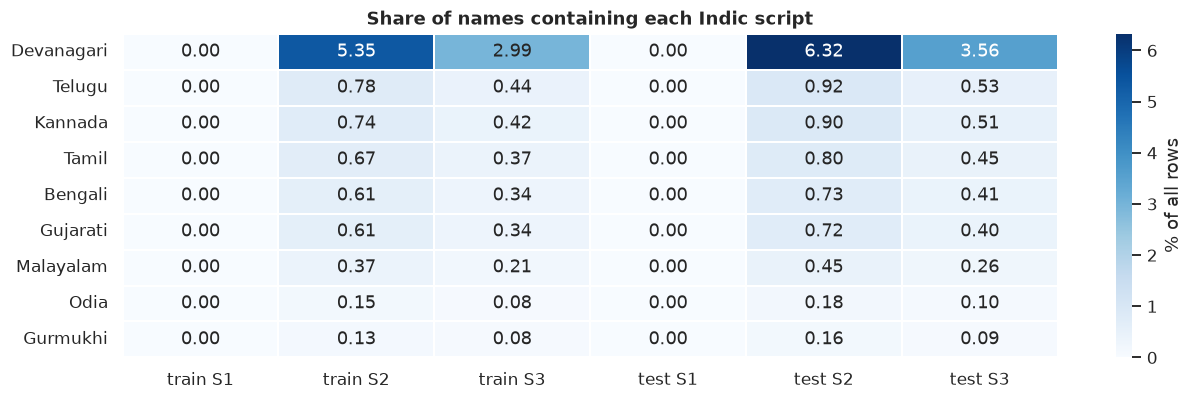

In [8]:
sc = pd.DataFrame({f"{s} {src}": pd.Series(r["scripts"]) / r["agg"].rows.sum() * 100 for (s, src), r in R.items()}).fillna(0)
sc = sc.loc[sc.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(sc, annot=True, fmt=".2f", cmap="Blues", linewidths=1, linecolor="white", cbar_kws={"label": "% of all rows"}, ax=ax)
ax.set_title("Share of names containing each Indic script"); plt.tight_layout(); plt.show()

## 8. Ground-truth structure

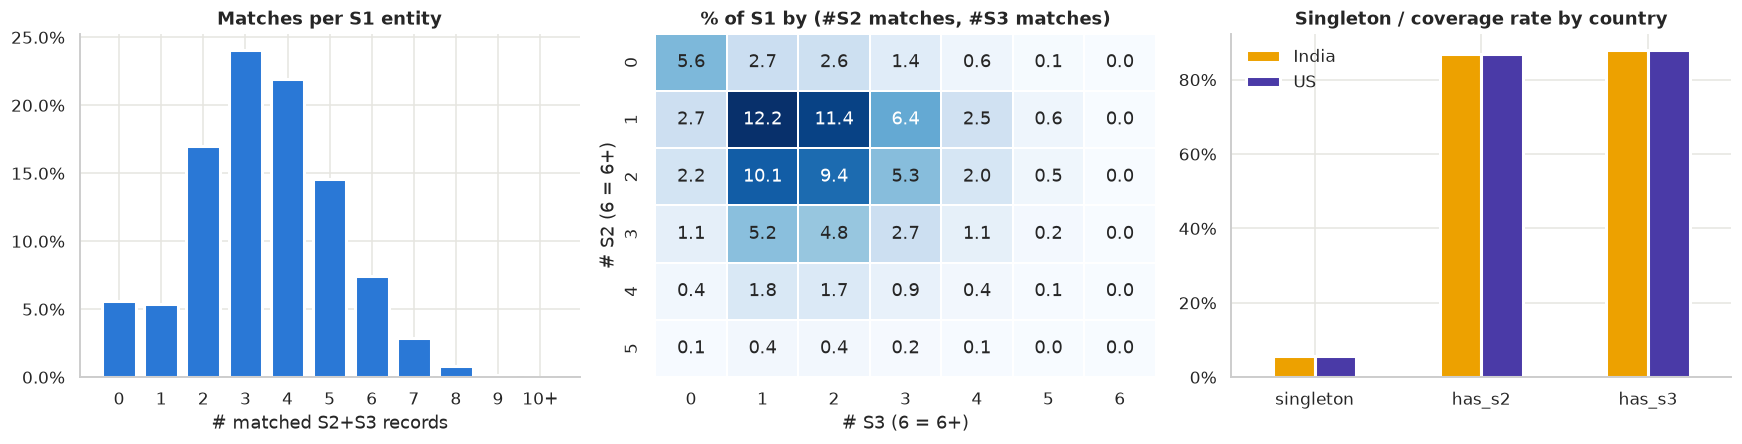

,file,country,matched,total,share_linked_to_some_S1
0,S2,India,1480545,2017799,73.4%
1,S2,US,2213074,3016817,73.4%
2,S3,India,1579298,2115547,74.7%
3,S3,US,2365448,3170056,74.6%


,count,mean,std,min,25%,50%,75%,max
country,,,,,,,,
India,883188.0,3.46,1.71,0.0,2.0,3.0,5.0,11.0
US,1323633.0,3.46,1.70,0.0,2.0,3.0,5.0,11.0


In [9]:
s1_train = R[("train", "S1")]["id_country"]
gt["id"] = id_to_int(gt.source1_entity_id)
gt = gt.merge(s1_train, on="id", how="left")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
vc = gt.n_match.clip(upper=10).value_counts().sort_index()
ax.bar(vc.index, vc.values / vc.sum(), color=SRC_COL["S1"], edgecolor="white", linewidth=2)
ax.set_xticks(range(11), [str(i) for i in range(10)] + ["10+"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title("Matches per S1 entity"); ax.set_xlabel("# matched S2+S3 records")

ax = axes[1]
ct = pd.crosstab(gt.n_s2.clip(upper=6), gt.n_s3.clip(upper=6), normalize="all") * 100
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax, linewidths=1, linecolor="white")
ax.set_title("% of S1 by (#S2 matches, #S3 matches)"); ax.set_xlabel("# S3 (6 = 6+)"); ax.set_ylabel("# S2 (6 = 6+)")

ax = axes[2]
by_c = gt.groupby("country").agg(singleton=("n_match", lambda x: (x == 0).mean()), has_s2=("n_s2", lambda x: (x > 0).mean()),
                                 has_s3=("n_s3", lambda x: (x > 0).mean()))
by_c.T.plot.bar(ax=ax, color=[CTRY_COL.get(c, "#888") for c in by_c.index], rot=0, edgecolor="white", linewidth=2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title("Singleton / coverage rate by country"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

dist = pd.DataFrame([{"file": src, "country": c, "matched": R[("train", src)]["distractor"][(c, "matched")],
                      "total": R[("train", src)]["distractor"][(c, "total")]}
                     for src in ["S2", "S3"] for c in R[("train", src)]["agg"].index])
dist["share_linked_to_some_S1"] = (dist.matched / dist.total).map("{:.1%}".format)
display(dist)
display(gt.groupby("country").n_match.describe().round(2))

## 9. Build pair samples: true matches vs. negatives

In [10]:
keep = pd.concat([R[k]["keep"] for k in R if k[0] == "train"], ignore_index=True)
cols = ["id_int", "entity_id", "business_name", "business_address", "country", "source"]
s1_rec = keep[(keep.source == "S1") & keep.id_int.isin(NEEDED["S1"])].drop_duplicates("id_int")[cols]
other = keep[keep.source != "S1"].drop_duplicates("id_int")[cols]

pos = (sample_pairs.merge(s1_rec.add_prefix("a_"), left_on="s1", right_on="a_id_int")
                   .merge(other.add_prefix("b_"), left_on="m", right_on="b_id_int"))
pos["label"] = "true match"

# Background pool = the random sample only (so negatives are realistic distractors)
bg = pd.concat([R[k]["keep"] for k in R if k[0] == "train" and k[1] != "S1"], ignore_index=True)
bg = bg[bg.is_bg].drop_duplicates("id_int")[cols]

# random negatives: same country, random record
a_side = s1_rec.add_prefix("a_")
rand_neg = []
for c, grp in a_side.groupby("a_country"):
    pool = bg[bg.country == c]
    if len(pool) == 0: continue
    b = pool.sample(len(grp), replace=True, random_state=SEED).add_prefix("b_").reset_index(drop=True)
    rand_neg.append(pd.concat([grp.reset_index(drop=True), b], axis=1))
rand_neg = pd.concat(rand_neg); rand_neg["label"] = "random negative"

# hard negatives: share the first 'core' name token (legal words removed) and same country
LEGAL = set(("pvt private ltd limited llp llc inc corp corporation co company the and of sarl sas sasu sa eurl sci "
              "group services service india industries enterprises international trust foundation").split())
def first_core(s):
    toks = [t for t in re.findall(r"\w+", s.lower()) if t not in LEGAL and len(t) > 2]
    return toks[0] if toks else ""
a_side = a_side.assign(k=a_side.a_business_name.map(first_core))
bgk = bg.assign(k=bg.business_name.map(first_core)).add_prefix("b_")
hard = a_side[a_side.k != ""].merge(bgk[bgk.b_k != ""], left_on=["k", "a_country"], right_on=["b_k", "b_country"])
hard = hard.merge(sample_pairs.assign(is_true=1), left_on=["a_id_int", "b_id_int"], right_on=["s1", "m"], how="left")
hard = hard[hard.is_true.isna()].groupby("a_id_int").sample(1, random_state=SEED)
hard["label"] = "hard negative"

P = pd.concat([pos, rand_neg, hard], ignore_index=True)[[c for c in pos.columns if c.startswith(("a_", "b_"))] + ["label"]]
print(P.label.value_counts())

label
true match         103868
random negative     30000
hard negative       26289
Name: count, dtype: int64


## 10. How separable are matches? (string similarity, raw fields)

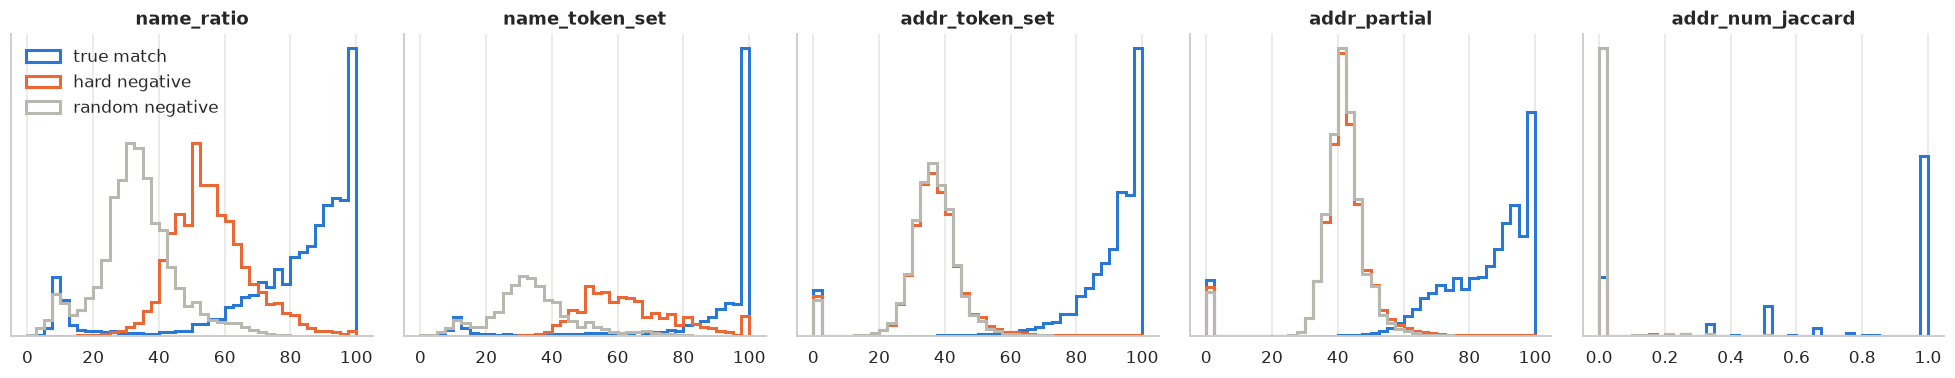

vs,hard negative,random negative
feature,,
addr_num_jaccard,0.897,0.897
addr_partial,0.952,0.955
addr_token_set,0.954,0.955
name_ratio,0.854,0.914
name_token_set,0.844,0.915


In [11]:
def norm(s):
    s = unicodedata.normalize("NFKC", s).lower()
    return re.sub(r"[^\w\s]", " ", s)

def sims(df):
    an, bn = df.a_business_name.map(norm), df.b_business_name.map(norm)
    aa, ba = df.a_business_address.map(norm), df.b_business_address.map(norm)
    out = pd.DataFrame(index=df.index)
    out["name_ratio"] = [fuzz.ratio(x, y) for x, y in zip(an, bn)]
    out["name_token_set"] = [fuzz.token_set_ratio(x, y) for x, y in zip(an, bn)]
    out["addr_token_set"] = [fuzz.token_set_ratio(x, y) for x, y in zip(aa, ba)]
    out["addr_partial"] = [fuzz.partial_ratio(x, y) for x, y in zip(aa, ba)]
    num = lambda s: set(re.findall(r"\d+", s))
    out["addr_num_jaccard"] = [len(num(x) & num(y)) / max(1, len(num(x) | num(y))) for x, y in zip(aa, ba)]
    return out

S = pd.concat([P, sims(P)], axis=1)
FEATS = ["name_ratio", "name_token_set", "addr_token_set", "addr_partial", "addr_num_jaccard"]

fig, axes = plt.subplots(1, len(FEATS), figsize=(18, 3.6), sharey=False)
for ax, f in zip(axes, FEATS):
    for lab, col in PAIR_COL.items():
        v = S.loc[S.label == lab, f]
        ax.hist(v, bins=40, range=(0, 100 if f != "addr_num_jaccard" else 1), density=True, histtype="step", lw=2, color=col, label=lab)
    ax.set_title(f); ax.set_yticks([])
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

auc = []
for f in FEATS:
    for neg in ["hard negative", "random negative"]:
        d = S[S.label.isin(["true match", neg])]
        auc.append({"feature": f, "vs": neg, "AUC": roc_auc_score(d.label == "true match", d[f])})
auc = pd.DataFrame(auc).pivot(index="feature", columns="vs", values="AUC").round(3)
auc

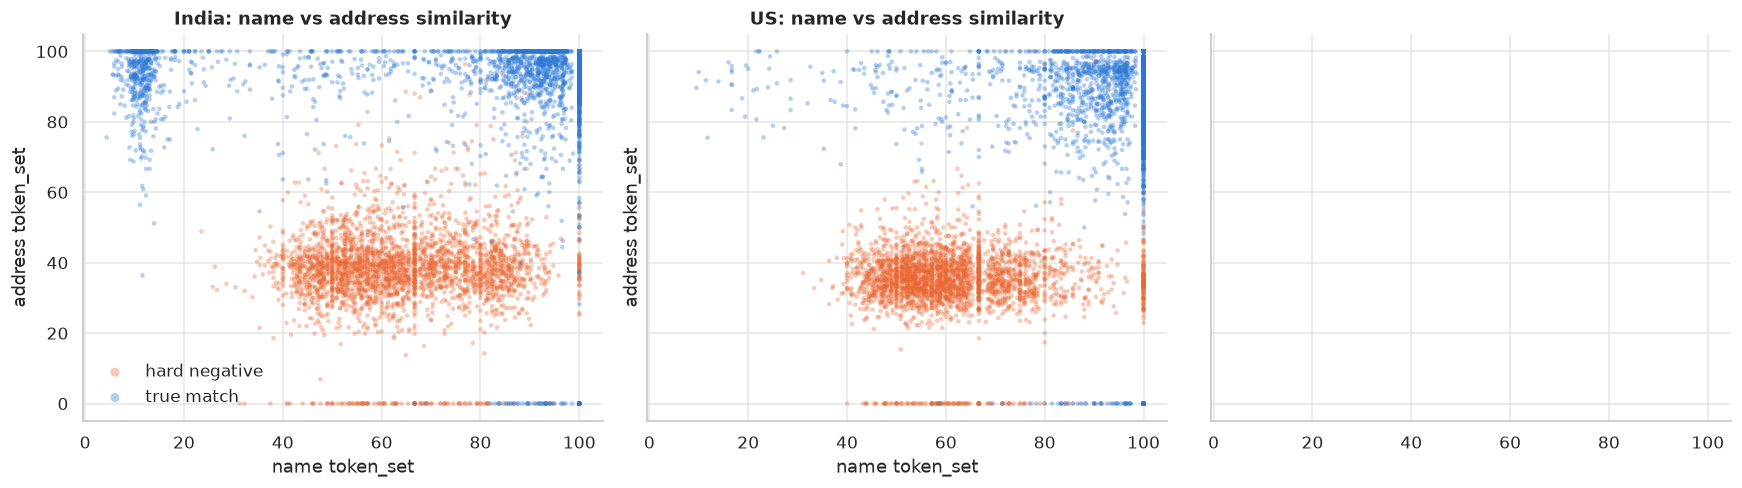

name_ratio  name_token_set  addr_token_set  addr_partial  \
a_country b_source                                                             
India     S2              81.0            93.1            99.5          90.9   
          S3              82.0            95.3            93.6          85.0   
US        S2              89.7           100.0            94.9          85.7   
          S3              88.9           100.0            87.3          89.7   

                    addr_num_jaccard  
a_country b_source                    
India     S2                     1.0  
          S3                     1.0  
US        S2                     1.0  
          S3                     1.0

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for ax, (c, g) in zip(axes, S[S.label != "random negative"].groupby("a_country")):
    for lab in ["hard negative", "true match"]:
        d = g[g.label == lab].sample(min(3000, (g.label == lab).sum()), random_state=SEED)
        ax.scatter(d.name_token_set, d.addr_token_set, s=9, alpha=0.35, color=PAIR_COL[lab], label=lab, edgecolors="none")
    ax.set_title(f"{c}: name vs address similarity"); ax.set_xlabel("name token_set"); ax.set_ylabel("address token_set")
axes[0].legend(frameon=False, markerscale=2)
plt.tight_layout(); plt.show()

# Similarity by (source of match, country): S2 and S3 behave differently
S[S.label == "true match"].groupby(["a_country", "b_source"])[FEATS].median().round(1)

## 11. Noise patterns: sample matched groups

In [13]:
pd.set_option("display.max_colwidth", 90)
for s1id in rng.choice(pos.a_id_int.unique(), 6, replace=False):
    g = pos[pos.a_id_int == s1id]
    head = g.iloc[0]
    rows_ = [("S1", head.a_business_name, head.a_business_address, head.a_country)] + \
            [(r.b_source, r.b_business_name, r.b_business_address, r.b_country) for r in g.itertuples()]
    display(pd.DataFrame(rows_, columns=["src", "name", "address", "country"]).style.hide(axis="index"))

src,name,address,country
S1,Chiropractic Care,"4335 Woodland Avenue, Cleveland, OH",US
S2,Chiropractic Care,"##4335 WOODLAND AVE, CLEVELAND, OH",US
S3,Chiropractic Cáre,"Woodland Avenue, Cleveland, Ohio",US


src,name,address,country
S1,Ram Agro Pvt Ltd,"C/O Golgunda Burla, Burla, Sambalpur, Orissa",India
S2,ରାମ ଆଗ୍ରୋ ପ୍ରାଇଭେଟ୍ ଲିମିଟେଡ୍,"C/O GOLGUNDA BURLA, BURLA, SAMBALPUR, Odisha",India
S2,ରାମ ଆଗ୍ରୋ ପ୍ରାଇଭେଟ୍ ଲିମିଟେଡ୍,"C/O GOLGUNDA BURLA, BURLA, SAMBALPUR, Odisha",India
S3,ରାମ Agro ପ୍ରାଇଭେଟ୍ ଲିମିଟେଡ୍,"C/o Golgunda Burla, Sambalpur, Burla, OD",India


src,name,address,country
S1,Sree Engineering Private Limited,"229, Tirupati Avenue, Panchkosi Marg, Bapna Park Colony, Ujjain, Madhya Pradesh",India
S2,Sree Éngineering Private Limited,"229, TIRUPATI AVENUE, PANCHKOSI MARG, BAPNA PARK COLONY, UJJAIN, मध्य प्रदेश",India
S3,Sree Private Limited Services,"227, Tirupati Avenue, Panchkosi Marg, Bapna Park Colony, Ujjain, MP",India
S3,sreeengineering.com,"227, Tirupati Avenue, Panchkosi Marg, Bapna Park Colony, Ujjain, MP",India
S3,Sree Engineering Pavge Limited,"227, Tirupati Avenue, Panchkosi Marg, Bapna Park Colony, Ujjain, मध्य प्रदेश",India


src,name,address,country
S1,Primary Care Partners LLC,"2914 Arlington Ct, Jeffersontown, KY",US
S2,Primary Care Partners,"2914 ARLINGTON CT, JEFFERSONTOWN, KY",US
S2,Primary Care LLC Partners,"2914 ARLINGTON CT, JEFFERSONTOWN, KY",US
S3,Primary-Care,"2914 Arlington Ct, Jeffersontown, Kentucky",US
S3,Primary Care Partners,"2914 Arlington Ct, Jeffersontown, Kentucky",US


src,name,address,country
S1,Township Of PC,"5692 Cedar Beach Lane, Town Of Belgium, WI",US
S2,TOWNSHIP PC OF,"5692 Cedar Beach Ln, TOWN OF BELGIUM, WI",US
S3,Township Of Pc,"5692 Cedar Beach Ln, Town Of Belgium, Wisconsin",US


src,name,address,country
S1,Blakeley Sweeney Legacy Idaho LLC,"4006 Sequoia Trail, Georgetown, TX",US
S2,BLAKELEY SWEENEY LEGACY IDAHO LLC,"4006 SEQUOIA TRAIL, GEORGETOWN, TX",US
S3,Blakeley Swfenfesy Legacy Idaho LLC,"4029 Sequoia Trl, Georgetown, Texas",US
S3,Blakeley Sweeney-Legacy Idaho LLC,"4006 Sequoia Trl, Georgetown, Texas",US


## 12. Token vocabulary: legal suffixes and address abbreviations

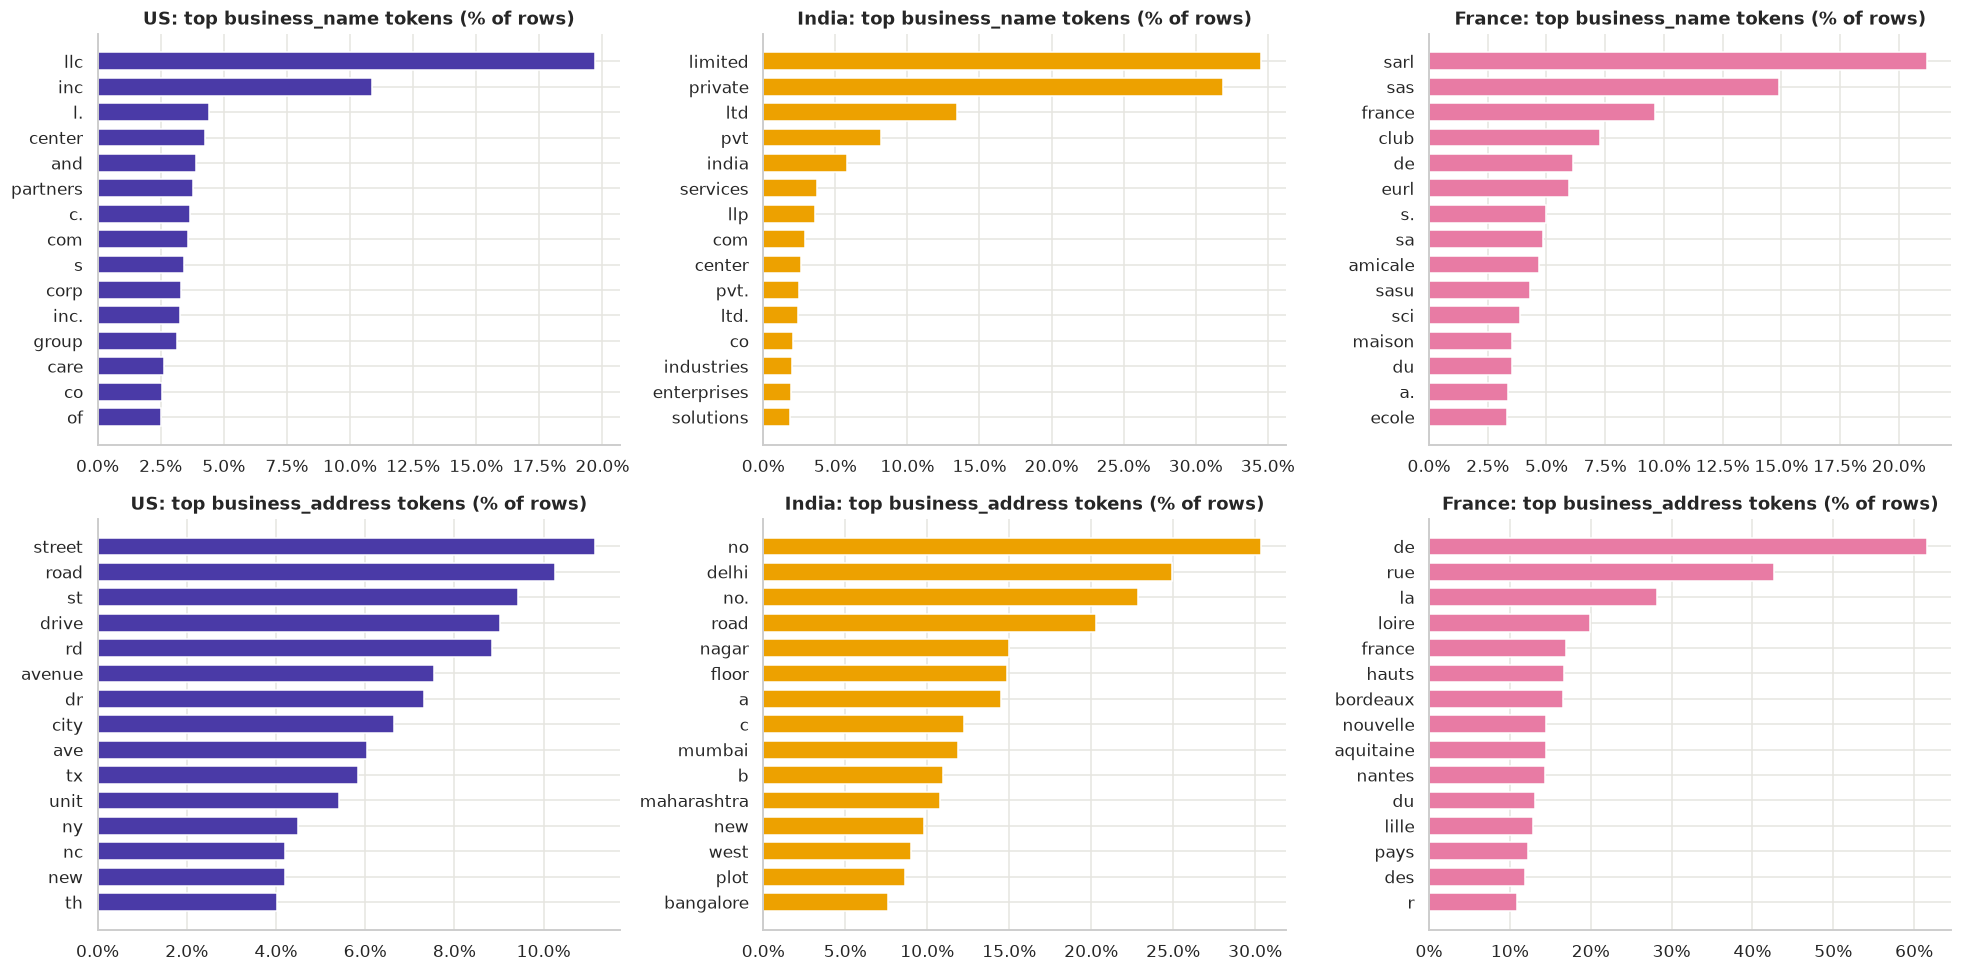

pvt|private  ltd|limited  inc|incorporated  corp|corporation  \
split source                                                                 
test  S1             29.3         35.5               6.9               1.9   
      S2             16.8         21.8               5.5               3.5   
      S3             19.4         25.0               5.4               3.2   
train S1             25.2         30.4              10.7               2.4   
      S2             14.5         18.2               8.4               3.9   
      S3             16.2         20.3               8.4               3.5   

              &|and  st|street  rd|road  ave|avenue  r.|rue  bd|boulevard  \
split source                                                                
test  S1        8.1       10.7     19.1         7.9     9.9           1.4   
      S2        7.1        9.7     17.8         7.2     5.9           0.9   
      S3        6.9        9.3     15.3         7.2     6.1           0.9   
train S1        8.7       14.9     21.8         9.0     0.2           1.0   
      S2        7.4       13.4     19.9         8.5     0.2           0.5   
      S3        7.2       13.2     17.9         8.4     0.2           0.5   

              near|opp  h.no|house  
split source                        
test  S1           5.2         3.7  
      S2           4.6         5.4  
      S3           3.3         5.1  
train S1           4.4         3.2  
      S2           3.8         4.5  
      S3           2.9         4.1

In [14]:
allk = pd.concat([R[k]["keep"] for k in R], ignore_index=True)
def top_tokens(series, n=15):
    c = Counter()
    for s in series:
        c.update(re.findall(r"[a-zà-ÿ]+\.?", s.lower()))  # Latin tokens only (plot fonts lack Indic glyphs)
    return c.most_common(n)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for j, c in enumerate(["US", "India", "France"]):
    for i, field in enumerate(["business_name", "business_address"]):
        ax = axes[i, j]
        d = allk[allk.country == c]
        if len(d) == 0: ax.axis("off"); continue
        tt = pd.DataFrame(top_tokens(d[field]), columns=["tok", "n"])
        ax.barh(tt.tok, tt.n / len(d), color=CTRY_COL[c], height=0.7)
        ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_title(f"{c}: top {field} tokens (% of rows)")
plt.tight_layout(); plt.show()

# Abbreviation pairs worth canonicalising, and how often each variant shows up, per source
VARIANTS = {"pvt|private": r"\b(?:pvt\.?|private)\b", "ltd|limited": r"\b(?:ltd\.?|limited)\b", "inc|incorporated": r"\b(?:inc\.?|incorporated)\b",
            "corp|corporation": r"\b(?:corp\.?|corporation)\b", "&|and": r"(?:&|\band\b)", "st|street": r"\b(?:st\.?|street)\b",
            "rd|road": r"\b(?:rd\.?|road)\b", "ave|avenue": r"\b(?:ave?\.?|avenue)\b", "r.|rue": r"\b(?:r\.|rue)\b", "bd|boulevard": r"\b(?:bd\.?|bld|boulevard)\b",
            "near|opp": r"\b(?:near|opp\.?|opposite|behind)\b", "h.no|house": r"\b(?:h\.?\s?no\.?|house)\b"}
var = pd.DataFrame({k: allk.groupby(["split", "source"]).apply(
    lambda d: (d.business_name + " " + d.business_address).str.contains(v, case=False, regex=True).mean() * 100)
    for k, v in VARIANTS.items()}).round(1)
var

## 13. ID leakage check

In [15]:
# If ID numbers were assigned sequentially per entity, matched pairs would have correlated IDs.
from scipy.stats import spearmanr
r_, p_ = spearmanr(pos.a_id_int % 10**10, pos.b_id_int % 10**10)
print(f"Spearman(S1 id number, matched id number) = {r_:.4f} (p={p_:.2g}); a value near 0 means no leakage")

Spearman(S1 id number, matched id number) = 0.0065 (p=0.037); a value near 0 means no leakage


## 14. Train vs. test drift

In [16]:
drift = quality.reset_index()
drift["split"] = drift.file.str.split().str[0]; drift["source"] = drift.file.str.split().str[1]
cmp_cols = ["nonascii_name", "indic_name", "empty_addr", "pin6_addr", "zip5_addr", "upper_addr", "avg_name_len", "avg_addr_len"]
dd = drift.pivot_table(index=["source", "country"], columns="split", values=cmp_cols)
dd = dd.reindex(columns=["train", "test"], level=1).round(3)
dd

avg_addr_len         avg_name_len         empty_addr         \
split                 train    test        train    test      train   test   
source country                                                               
S1     France           NaN  50.071          NaN  19.423        NaN  0.000   
       India         77.700  77.714       26.386  26.375      0.000  0.000   
       US            34.962  34.966       22.465  22.463      0.000  0.000   
S2     France           NaN  39.548          NaN  21.103        NaN  0.031   
       India         68.196  68.745       27.420  28.251      0.029  0.023   
       US            31.531  31.843       23.554  24.285      0.037  0.029   
S3     France           NaN  39.969          NaN  21.140        NaN  0.029   
       India         59.106  59.420       27.038  27.867      0.031  0.025   
       US            38.445  38.838       23.977  24.619      0.035  0.028   

               indic_name        nonascii_name        pin6_addr         \
split               train   test         train   test     train   test   
source country                                                           
S1     France         NaN  0.000           NaN  0.157       NaN  0.000   
       India        0.000  0.000         0.000  0.000     0.004  0.004   
       US           0.000  0.000         0.000  0.000     0.007  0.007   
S2     France         NaN  0.000           NaN  0.245       NaN  0.000   
       India        0.235  0.236         0.279  0.276     0.012  0.012   
       US           0.000  0.000         0.067  0.062     0.019  0.019   
S3     France         NaN  0.000           NaN  0.239       NaN  0.000   
       India        0.132  0.133         0.185  0.182     0.011  0.011   
       US           0.000  0.000         0.068  0.064     0.018  0.019   

               upper_addr        zip5_addr         
split               train   test     train   test  
source country                                     
S1     France         NaN  0.000       NaN  0.004  
       India        0.000  0.000     0.003  0.003  
       US           0.000  0.000     0.109  0.109  
S2     France         NaN  0.290       NaN  0.005  
       India        0.239  0.240     0.011  0.011  
       US           0.898  0.905     0.105  0.107  
S3     France         NaN  0.000       NaN  0.005  
       India        0.000  0.000     0.010  0.010  
       US           0.000  0.000     0.105  0.107

## 15. Auto-generated summary

In [17]:
tot = lambda s, src: int(R[(s, src)]["agg"].rows.sum())
fr = ctry[(ctry.country == "France")].set_index(["split", "source"]).share
sing = (gt.n_match == 0).mean()
pos_m = S[S.label == "true match"][FEATS].median()
hard_m = S[S.label == "hard negative"][FEATS].median()
lines = [
    "# EDA summary: ML Challenge 2026 Business Entity Resolution",
    f"_Generated by data_vis.ipynb ({'FULL data' if MAX_ROWS is None else f'first {MAX_ROWS:,} rows/file'})_",
    "",
    "## Volume",
    f"- Train: S1 {tot('train','S1'):,} · S2 {tot('train','S2'):,} · S3 {tot('train','S3'):,}",
    f"- Test: S1 {tot('test','S1'):,} · S2 {tot('test','S2'):,} · S3 {tot('test','S3'):,}",
    f"- A naive all-pairs comparison on test would be {tot('test','S1') * (tot('test','S2') + tot('test','S3')):.2e} pairs, so blocking is mandatory.",
    "",
    "## Countries",
    "- Train covers " + ", ".join(sorted(R[('train','S1')]['agg'].index)) + "; test covers " + ", ".join(sorted(R[('test','S1')]['agg'].index)) + ".",
    "- France share in test: " + ", ".join(f"{k[1]} {v:.1%}" for k, v in fr.items()) + ".",
    "",
    "## Ground truth",
    f"- {len(gt):,} S1 entities. Singletons (no match): **{sing:.1%}**. Mean matches per S1: {gt.n_match.mean():.2f} (S2 {gt.n_s2.mean():.2f}, S3 {gt.n_s3.mean():.2f}). Max: {gt.n_match.max()}.",
    f"- S2/S3 records linked to more than one S1: **{dup_targets:,}**, so the link structure is a partition (each S2/S3 record belongs to at most one S1).",
    "- Share of train S2/S3 records that belong to *some* S1 (the rest are distractors): " +
        "; ".join(f"{r.file}-{r.country} {r.matched / r.total:.1%}" for r in dist.itertuples()) + ".",
    "- Singleton rate by country: " + ", ".join(f"{c} {v:.1%}" for c, v in by_c.singleton.items()) + ".",
    "",
    "## Separability (sampled pairs, raw normalised strings)",
    "- Median similarity, true match vs hard negative: " + ", ".join(f"{f} {pos_m[f]:.0f} vs {hard_m[f]:.0f}" if f != 'addr_num_jaccard' else f"{f} {pos_m[f]:.2f} vs {hard_m[f]:.2f}" for f in FEATS) + ".",
    "- AUC vs hard negatives: " + ", ".join(f"{f} {auc.loc[f, 'hard negative']:.3f}" for f in FEATS) + ".",
    "",
    "## Noise",
    "- Exact (name, address) duplicate rate: " + ", ".join(f"{k} {v:.2%}" for k, v in dup.items()) + ".",
    "- Names containing Indic script: " + ", ".join(f"{f} {quality.loc[(f, 'India'), 'indic_name']:.1%}" for f in quality.index.get_level_values(0).unique() if (f, "India") in quality.index) + " (India rows).",
    "- Empty address: " + ", ".join(f"{f}/{c} {v:.1%}" for (f, c), v in quality.empty_addr.items() if v > 0.001) + ".",
    f"- ID leakage: Spearman ρ between S1 and matched ID numbers = {r_:.3f}, so none.",
    "",
    f"_Runtime: {(time.time() - t0) / 60:.1f} min_",
]
summary = "\n".join(lines)
Path("eda_summary.md").write_text(summary + "\n")
display(Markdown(summary))

# EDA summary: ML Challenge 2026 Business Entity Resolution
_Generated by data_vis.ipynb (FULL data)_

## Volume
- Train: S1 2,206,821 · S2 5,034,616 · S3 5,285,603
- Test: S1 1,732,544 · S2 4,887,273 · S3 5,082,316
- A naive all-pairs comparison on test would be 1.73e+13 pairs, so blocking is mandatory.

## Countries
- Train covers India, US; test covers France, India, US.
- France share in test: S1 15.0%, S2 14.4%, S3 14.4%.

## Ground truth
- 2,206,821 S1 entities. Singletons (no match): **5.6%**. Mean matches per S1: 3.46 (S2 1.67, S3 1.79). Max: 11.
- S2/S3 records linked to more than one S1: **0**, so the link structure is a partition (each S2/S3 record belongs to at most one S1).
- Share of train S2/S3 records that belong to *some* S1 (the rest are distractors): S2-India 73.4%; S2-US 73.4%; S3-India 74.7%; S3-US 74.6%.
- Singleton rate by country: India 5.6%, US 5.6%.

## Separability (sampled pairs, raw normalised strings)
- Median similarity, true match vs hard negative: name_ratio 87 vs 55, name_token_set 100 vs 61, addr_token_set 94 vs 37, addr_partial 88 vs 42, addr_num_jaccard 1.00 vs 0.00.
- AUC vs hard negatives: name_ratio 0.854, name_token_set 0.844, addr_token_set 0.954, addr_partial 0.952, addr_num_jaccard 0.897.

## Noise
- Exact (name, address) duplicate rate: train S1 0.00%, train S2 0.51%, train S3 0.36%, test S1 0.00%, test S2 0.46%, test S3 0.32%.
- Names containing Indic script: train S1 0.0%, train S2 23.5%, train S3 13.2%, test S1 0.0%, test S2 23.6%, test S3 13.3% (India rows).
- Empty address: train S2/India 2.9%, train S2/US 3.7%, train S3/India 3.1%, train S3/US 3.5%, test S2/France 3.1%, test S2/India 2.3%, test S2/US 2.9%, test S3/France 2.9%, test S3/India 2.5%, test S3/US 2.8%.
- ID leakage: Spearman ρ between S1 and matched ID numbers = 0.006, so none.

_Runtime: 6.9 min_

## 16. Recommended pipeline for maximising test F0.5

The metric is **per-S1 macro F0.5, and singletons count**. A single false positive on a singleton costs a full 1.0 for that entity. The decision layer (when to predict an *empty* list, and when to stop adding matches) therefore matters as much as the matcher itself.

### Stage 0: Validation that mirrors test
- Hold out ~10% of train **S1 entities**. Run blocking against the **full** train S2/S3 pool, distractors included, and score with the exact macro F0.5.
- **Leave-one-country-out** (train on US, validate on India, and the reverse) is the proxy for the unseen **France** slice. Track that score separately.

### Stage 1: Normalisation (country-agnostic, rule-based)
- Unicode NFKC, lowercase, strip junk prefixes and brackets, collapse whitespace, and drop `null` tokens.
- **Transliterate** Indic scripts to Latin (e.g. `indic-transliteration`, `anyascii`), and keep both the raw and transliterated forms.
- Canonicalise legal suffixes into a *separate* field. Cover US/India (`pvt, private, ltd, limited, llp, inc, corp, llc, co`) **and French** (`sarl, sas, sasu, sa, eurl, sci, & fils, frères`). Then compute a `core_name`.
- Address: expand abbreviations (`st, rd, ave, blvd, r., bd, av., opp, nr, h.no`), map state codes to names (`TX↔Texas`, `MH↔Maharashtra↔महाराष्ट्र`, French departments and regions), and extract **postal code** (6-digit PIN, 5-digit ZIP or CP), **house/plot numbers**, city, and state. Component order varies, so treat the address as a bag of components rather than a sequence.

### Stage 2: Blocking (union of several cheap keys, tuned for ~99% recall)
Candidates are the **union** of:
1. exact postal code + first core-name token
2. city/state + a phonetic key of the core name (Double Metaphone)
3. **char 3-gram TF-IDF on `core_name + city`** with top-k nearest neighbours (sparse dot-top-n or PyNNDescent)
4. **Multilingual sentence embeddings** (e.g. `multilingual-e5-small` or `paraphrase-multilingual-MiniLM-L12-v2`, both permissively licensed) with FAISS top-k. This catches Hindi/Tamil names against their Latin counterparts.

Block **within country** (never across). Measure *pair recall* and *entity-level recall ceiling* against k, and pick the smallest k that keeps about 98–99% recall. On 15 GB of RAM, run neighbour search per country/state partition and store embeddings as float16. Write this final set to `candidate_pairs.tsv`.

### Stage 3: Pairwise matcher (GBDT, then an optional cross-encoder)
- **LightGBM or XGBoost** on about 60–100 features:
  - name similarities: ratio, token_set, Jaro-Winkler, IDF-weighted Jaccard on core names, suffix agreement, and phonetic match
  - address similarities: token_set, **house-number overlap**, postal/city/state equality, and missing-field flags
  - embedding cosine and script flags
  - **within-candidate-list context**: rank of this candidate for its S1, gap to the best score, and number of candidates
  - the target source (S2 or S3)

  **Do not one-hot `country`.** Keep the features country-agnostic so the model transfers to France.
- Train on **blocking-generated negatives** (hard negatives by construction) and use GroupKFold by S1 id.
- Optionally re-score the top ~5 candidates with a small fine-tuned **cross-encoder** (e.g. `xlm-roberta-base` or `mdeberta-v3-base`, MIT). Its input is the concatenated `name | address` of both records. Blend its score with the GBDT score.

### Stage 4: Structured decision layer (where most of the F0.5 is won)
1. **Calibrate** probabilities (isotonic regression on out-of-fold predictions).
2. **One-to-one constraint:** the EDA shows each S2/S3 record belongs to at most one S1. Assign each S2/S3 candidate only to its highest-scoring S1, and drop it everywhere else.
3. **Group consistency:** true matches of one S1 are also similar to *each other* (S2↔S3). Add a second-pass feature, "mean similarity to the other accepted members", or run a small graph clustering step.
4. **Expected-F0.5 subset selection per S1.** Sort candidates by p. For each prefix size k (including k = 0), compute the expected F0.5 by Monte-Carlo sampling from the calibrated p, and output the argmax. This handles singletons correctly: the empty list is chosen when P(no match) is high enough. Tuning one global threshold is a weaker fallback.
5. Tune thresholds **separately for S2 and S3**, and use a stricter prior for unseen countries. For France, lean towards precision.

### Stage 5: France (no labels)
- Use the country-agnostic features above plus French normalisation rules.
- **Synthetic pairs:** take French test S1 records and generate noisy copies with the *noise operators measured in train* (abbreviations, typos, token swaps, dropped components, accent stripping), then fine-tune on them. Only the provided data is used.
- Optional self-training: add high-confidence France test pairs as pseudo-labels for one extra round. Check the challenge rules first.

### Stage 6: Packaging
Write `matching_results.tsv` and `candidate_pairs.tsv`, making sure every match is a subset of the candidates. Run `utils/validate_submission.py --check-ids` and fill in `Documentation_template.md` with the recall/F0.5 numbers from Stage 0.